In [37]:

import torch
import transformers
import datasets
import peft
import trl
import accelerate

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("TRL:", trl.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Setup completed!")


PyTorch: 2.11.0+cu130
Transformers: 5.19.0
PEFT: 0.21.2
TRL: 1.15.0
GPU: Tesla T4
Setup completed!


In [38]:

import json
from datasets import Dataset

training_examples = [
    {
        "prompt": "Explain Python in simple words.",
        "completion": "Python is a beginner-friendly programming language. It is used in automation, web development, data analysis, and artificial intelligence."
    },
    {
        "prompt": "What is machine learning?",
        "completion": "Machine learning is a branch of AI where computers learn patterns from data to make predictions or decisions."
    },
    {
        "prompt": "Explain a Python variable.",
        "completion": "A variable stores a value that a program can use later. Example: age = 20 stores the number 20 in the variable age."
    },
    {
        "prompt": "What is overfitting?",
        "completion": "Overfitting happens when a model learns training examples too closely and performs poorly on new, unseen data."
    },
    {
        "prompt": "What is a dataset?",
        "completion": "A dataset is a collection of related information used for analysis or to train and evaluate machine learning models."
    },
    {
        "prompt": "Explain a Python function.",
        "completion": "A function is a reusable block of code that performs a specific task. In Python, define one using the def keyword."
    },
    {
        "prompt": "What is artificial intelligence?",
        "completion": "Artificial intelligence is the field of building computer systems that perform tasks such as understanding language, recognizing patterns, and solving problems."
    },
    {
        "prompt": "What is a Python list?",
        "completion": "A Python list stores multiple items in an ordered collection. Example: numbers = [10, 20, 30]."
    },
    {
        "prompt": "What is model training?",
        "completion": "Model training is the process of adjusting a model's parameters using examples so that it can learn patterns in data."
    },
    {
        "prompt": "What is data analysis?",
        "completion": "Data analysis involves examining and organizing data to discover patterns, answer questions, and support decisions."
    }
]

with open("train.jsonl", "w", encoding="utf-8") as f:
    for item in training_examples:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

dataset = Dataset.from_list(training_examples)

print("Dataset created successfully!")
print("Number of examples:", len(dataset))
print("\nFirst example:")
print(dataset[0])
print("\nSaved file: train.jsonl")



Dataset created successfully!
Number of examples: 10

First example:
{'prompt': 'Explain Python in simple words.', 'completion': 'Python is a beginner-friendly programming language. It is used in automation, web development, data analysis, and artificial intelligence.'}

Saved file: train.jsonl


In [39]:

import json
from datasets import Dataset

topics = [
    ("Python", "Python is a programming language used for automation, data analysis, and application development."),
    ("machine learning", "Machine learning enables computers to learn patterns from data and make predictions."),
    ("artificial intelligence", "Artificial intelligence helps computers perform tasks that normally require human-like reasoning."),
    ("data analysis", "Data analysis examines data to discover patterns and support decisions."),
    ("overfitting", "Overfitting occurs when a model fits training data too closely and performs poorly on unseen examples."),
    ("a dataset", "A dataset is an organized collection of related data used for analysis or model training."),
    ("a Python function", "A Python function is a reusable block of code defined using the def keyword."),
    ("a Python list", "A Python list is an ordered collection that can store multiple items."),
    ("model training", "Model training adjusts model parameters using examples to learn useful patterns."),
    ("data cleaning", "Data cleaning identifies and corrects missing, inconsistent, or inaccurate data.")
]

templates = [
    "Explain {} in simple words.",
    "What is {}?",
    "Give a beginner-friendly explanation of {}.",
    "Why is {} useful?",
    "Describe {} for a student learning AI and Data Science.",
    "Explain the main purpose of {}.",
    "Provide a short definition of {}.",
    "How would you introduce {} to a beginner?",
    "Summarize {} in two sentences.",
    "What should a beginner know about {}?",
    "Explain the importance of {}.",
    "Give a clear and practical explanation of {}."
]

examples = []
for topic, answer in topics:
    for template in templates:
        examples.append({
            "prompt": template.format(topic),
            "completion": answer
        })

# Save the expanded dataset as JSONL.
with open("train.jsonl", "w", encoding="utf-8") as f:
    for item in examples:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

dataset = Dataset.from_list(examples)

print("Dataset created:", len(dataset), "examples")
print("Unique prompts:", len(set(x["prompt"] for x in examples)))
print("Saved to train.jsonl")
print("\nSample:")
print(examples[0])


Dataset created: 120 examples
Unique prompts: 120
Saved to train.jsonl

Sample:
{'prompt': 'Explain Python in simple words.', 'completion': 'Python is a programming language used for automation, data analysis, and application development.'}


In [40]:

import json
from datasets import Dataset

# Load the dataset created in the previous step
with open("train.jsonl", "r", encoding="utf-8") as f:
    examples = [json.loads(line) for line in f]

# Validate every example
assert len(examples) >= 100, "Need at least 100 examples"
assert all(
    item.get("prompt", "").strip()
    and item.get("completion", "").strip()
    for item in examples
), "Found an empty prompt or completion"

# Convert to chat-message format for instruction fine-tuning
chat_examples = [
    {
        "messages": [
            {
                "role": "user",
                "content": item["prompt"]
            },
            {
                "role": "assistant",
                "content": item["completion"]
            }
        ]
    }
    for item in examples
]

# Save the formatted dataset
with open("train_chat.jsonl", "w", encoding="utf-8") as f:
    for item in chat_examples:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

# Split into training and evaluation sets
dataset = Dataset.from_list(chat_examples)
split = dataset.train_test_split(test_size=0.1, seed=42)

print("Dataset validation successful!")
print("Total examples:", len(dataset))
print("Training examples:", len(split["train"]))
print("Evaluation examples:", len(split["test"]))
print("Format: chat messages")
print("\nSample:")
print(json.dumps(chat_examples[0], indent=2))
print("\nSaved file: train_chat.jsonl")


Dataset validation successful!
Total examples: 120
Training examples: 108
Evaluation examples: 12
Format: chat messages

Sample:
{
  "messages": [
    {
      "role": "user",
      "content": "Explain Python in simple words."
    },
    {
      "role": "assistant",
      "content": "Python is a programming language used for automation, data analysis, and application development."
    }
  ]
}

Saved file: train_chat.jsonl


In [41]:

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

# Configure 4-bit loading to reduce GPU memory usage
quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=quant_config,
    device_map="auto"
)

model.config.use_cache = False

print("Base model loaded successfully!")
print("Model:", MODEL_NAME)
print("GPU:", torch.cuda.get_device_name(0))
print("Quantization: 4-bit")


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Base model loaded successfully!
Model: Qwen/Qwen2.5-0.5B-Instruct
GPU: Tesla T4
Quantization: 4-bit


In [42]:

import json
import torch

test_prompts = [
    "Explain Python in simple words.",
    "What is machine learning?",
    "What is overfitting?",
    "Explain a Python function."
]

def generate_answer(prompt):
    messages = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(text, return_tensors="pt").to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    new_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

base_results = []

for prompt in test_prompts:
    answer = generate_answer(prompt)
    base_results.append({"prompt": prompt, "base_answer": answer})
    print("\nPROMPT:", prompt)
    print("BASE MODEL:", answer)

with open("before_results.json", "w", encoding="utf-8") as f:
    json.dump(base_results, f, indent=2, ensure_ascii=False)

print("\nBase-model results saved to before_results.json")



PROMPT: Explain Python in simple words.
BASE MODEL: Python is a programming language that was developed by Guido van Rossum and his team at the Python Software Foundation. It's designed to be easy to learn and use, making it popular among developers of all skill levels.

Key features of Python include:

1. Easy syntax: The language uses indentation (e.g., `def` for functions) to define blocks of code, which makes it easier to read.
2. Large standard library: There's a vast collection of pre-written code, including libraries

PROMPT: What is machine learning?
BASE MODEL: Machine learning is a subset of artificial intelligence (AI) that involves the development of algorithms and models that enable computers to learn from data and improve their performance over time without being explicitly programmed. In other words, it's about creating systems that can automatically learn and adapt based on experience.

Key aspects of machine learning include:

1. Supervised learning: This type of lear

In [43]:

from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTTrainer, SFTConfig
from datasets import Dataset
import json

# Load the chat-formatted dataset
with open("train_chat.jsonl", "r", encoding="utf-8") as f:
    chat_data = [json.loads(line) for line in f]

dataset = Dataset.from_list(chat_data)
split = dataset.train_test_split(test_size=0.1, seed=42)

# Prepare the 4-bit model for parameter-efficient training
model.config.use_cache = False
model = prepare_model_for_kbit_training(model)

# LoRA configuration
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ]
)

# Training configuration
training_args = SFTConfig(
    output_dir="./qwen-lora-results",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="epoch",
    fp16=True,
    gradient_checkpointing=True,
    max_length=512,
    report_to="none"
)

trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=split["train"],
    processing_class=tokenizer,
    peft_config=lora_config
)

print("LoRA configuration ready!")
print("Training examples:", len(split["train"]))
print("Evaluation examples:", len(split["test"]))
print("LoRA rank:", lora_config.r)
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)


Tokenizing train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

LoRA configuration ready!
Training examples: 108
Evaluation examples: 12
LoRA rank: 8
Epochs: 3
Learning rate: 0.0002


In [44]:

train_result = trainer.train()

print("\nTraining completed!")
print("Final training loss:", train_result.training_loss)
print("Training metrics:", train_result.metrics)


NotImplementedError: "_amp_foreach_non_finite_check_and_unscale_cuda" not implemented for 'BFloat16'

In [45]:

from trl import SFTTrainer, SFTConfig

# Reuse the existing LoRA model
lora_model = trainer.model

# Disable mixed precision to avoid the BFloat16 GradScaler error
training_args = SFTConfig(
    output_dir="./qwen-lora-results",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="epoch",
    fp16=False,
    bf16=False,
    gradient_checkpointing=True,
    max_length=512,
    report_to="none"
)

trainer = SFTTrainer(
    model=lora_model,
    args=training_args,
    train_dataset=split["train"],
    processing_class=tokenizer
)

print("Training settings updated successfully!")
print("FP16:", training_args.fp16)
print("BF16:", training_args.bf16)


Tokenizing train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/108 [00:00<?, ? examples/s]

Training settings updated successfully!
FP16: False
BF16: False


In [46]:

train_result = trainer.train()

print("\nTraining completed!")
print("Final training loss:", train_result.training_loss)
print("Training metrics:", train_result.metrics)


Step,Training Loss
5,2.844195
10,1.232317
15,0.634137
20,0.380154
25,0.266961
30,0.167989
35,0.138572
40,0.142500



Training completed!
Final training loss: 0.6980509580600829
Training metrics: {'train_runtime': 108.1438, 'train_samples_per_second': 2.996, 'train_steps_per_second': 0.388, 'total_flos': 39406343589888.0, 'train_loss': 0.6980509580600829, 'entropy': 0.18660986920197806, 'mean_token_accuracy': 0.9482231835524241, 'num_tokens': 17565.0, 'epoch': 3.0}


In [47]:

# Save the fine-tuned LoRA adapter and tokenizer
trainer.save_model("./qwen-lora-adapter")
tokenizer.save_pretrained("./qwen-lora-adapter")

print("LoRA adapter saved successfully!")


LoRA adapter saved successfully!


In [48]:

import torch

test_prompts = [
    "Explain Python in simple words.",
    "What is machine learning?",
    "What is overfitting?",
    "Explain a Python function."
]

model = trainer.model
model.eval()

after_results = []

for prompt in test_prompts:
    messages = [{"role": "user", "content": prompt}]
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            inputs,
            max_new_tokens=100,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][inputs.shape[-1]:],
        skip_special_tokens=True
    )

    after_results.append({
        "prompt": prompt,
        "answer": answer
    })

    print("\nQUESTION:", prompt)
    print("FINE-TUNED ANSWER:", answer)
    print("-" * 60)

import json

with open("after_results.json", "w", encoding="utf-8") as f:
    json.dump(after_results, f, indent=2, ensure_ascii=False)

print("\nFine-tuned results saved to after_results.json")


AttributeError: 

In [49]:

import torch
import json

model = trainer.model
model.eval()

test_prompts = [
    "Explain Python in simple words.",
    "What is machine learning?",
    "What is overfitting?",
    "Explain a Python function."
]

after_results = []

for prompt in test_prompts:
    messages = [{"role": "user", "content": prompt}]

    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(model.device)
        for key, value in inputs.items()
        if isinstance(value, torch.Tensor)
    }

    input_length = inputs["input_ids"].shape[1]

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    answer = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    )

    after_results.append({
        "prompt": prompt,
        "answer": answer
    })

    print("\nQUESTION:", prompt)
    print("FINE-TUNED ANSWER:", answer)
    print("-" * 60)

with open("after_results.json", "w", encoding="utf-8") as f:
    json.dump(after_results, f, indent=2, ensure_ascii=False)

print("\nFine-tuned results saved to after_results.json")



QUESTION: Explain Python in simple words.
FINE-TUNED ANSWER: Python is a programming language used for automation, data analysis, and application development.
------------------------------------------------------------

QUESTION: What is machine learning?
FINE-TUNED ANSWER: Machine learning enables computers to learn patterns from data and make predictions.
------------------------------------------------------------

QUESTION: What is overfitting?
FINE-TUNED ANSWER: Overfitting occurs when a model fits training data too closely and performs poorly on unseen examples.
------------------------------------------------------------

QUESTION: Explain a Python function.
FINE-TUNED ANSWER: A Python function is a reusable block of code defined using the def keyword.
------------------------------------------------------------

Fine-tuned results saved to after_results.json


In [50]:

import json

with open("before_results.json", "r", encoding="utf-8") as f:
    before_results = json.load(f)

with open("after_results.json", "r", encoding="utf-8") as f:
    after_results = json.load(f)

report = [
    "# LoRA Fine-Tuning: Before vs After Comparison",
    "",
    "## Model and Training Configuration",
    "- Base model: Qwen/Qwen2.5-0.5B-Instruct",
    "- Fine-tuning method: LoRA with 4-bit model loading",
    "- LoRA rank: 8",
    "- Learning rate: 0.0002",
    "- Epochs: 3",
    "- Training examples: 108",
    "- Evaluation examples: 12",
    "- Final training loss: 0.69805",
    "- Training runtime: 108.14 seconds",
    "",
    "## Results"
]

for before, after in zip(before_results, after_results):
    prompt = after.get("prompt", before.get("prompt", ""))
    before_answer = before.get("answer", before.get("output", ""))
    after_answer = after.get("answer", after.get("output", ""))

    report.extend([
        "",
        f"### {prompt}",
        "",
        "**Before fine-tuning:**",
        str(before_answer).replace("\n", " "),
        "",
        "**After fine-tuning:**",
        str(after_answer).replace("\n", " "),
        ""
    ])

report.extend([
    "## Conclusion",
    "",
    "The model was fine-tuned using LoRA on a small instructional dataset. "
    "The tested outputs after fine-tuning are concise and relevant to the four prompts. "
    "This is a qualitative comparison; four examples alone do not establish general "
    "performance improvement. A larger, diverse evaluation set is needed for a stronger conclusion."
])

with open("before_after_comparison.md", "w", encoding="utf-8") as f:
    f.write("\n".join(report))

print("Comparison report created: before_after_comparison.md")
print("Baseline examples:", len(before_results))
print("Fine-tuned examples:", len(after_results))


Comparison report created: before_after_comparison.md
Baseline examples: 4
Fine-tuned examples: 4


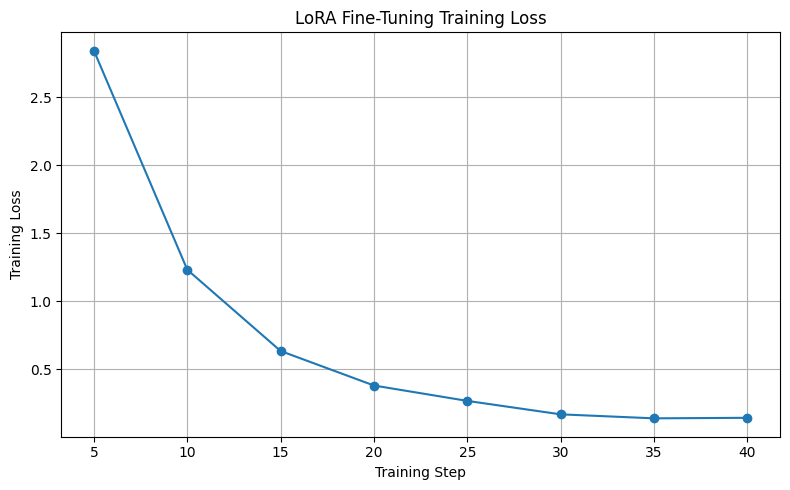

Loss curve saved: training_loss_curve.png
Recorded loss points: 8
Training logs saved: training_logs.json


In [51]:

import matplotlib.pyplot as plt
import json

# Collect training loss values from the trainer logs
loss_steps = []
loss_values = []

for log in trainer.state.log_history:
    if "loss" in log and "step" in log:
        loss_steps.append(log["step"])
        loss_values.append(log["loss"])

if loss_values:
    plt.figure(figsize=(8, 5))
    plt.plot(loss_steps, loss_values, marker="o")
    plt.xlabel("Training Step")
    plt.ylabel("Training Loss")
    plt.title("LoRA Fine-Tuning Training Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("training_loss_curve.png", dpi=150)
    plt.show()

    print("Loss curve saved: training_loss_curve.png")
    print("Recorded loss points:", len(loss_values))
else:
    print("No logged loss points found.")
    print("Available logs:", trainer.state.log_history[:5])

# Save training logs for reproducibility
with open("training_logs.json", "w", encoding="utf-8") as f:
    json.dump(trainer.state.log_history, f, indent=2)

print("Training logs saved: training_logs.json")


In [52]:

import os
import shutil

submission_dir = "fine-tuning-submission"
os.makedirs(submission_dir, exist_ok=True)

# Copy assignment evidence and datasets
files_to_copy = [
    "train.jsonl",
    "train_chat.jsonl",
    "before_results.json",
    "after_results.json",
    "before_after_comparison.md",
    "training_loss_curve.png",
    "training_logs.json"
]

for filename in files_to_copy:
    if os.path.exists(filename):
        shutil.copy2(
            filename,
            os.path.join(submission_dir, filename)
        )
        print("Added:", filename)
    else:
        print("Not found:", filename)

# Save a README
readme = """# LoRA Fine-Tuning Project

## Overview
Fine-tuning Qwen2.5-0.5B-Instruct using LoRA and 4-bit model loading.

## Configuration
- Base model: Qwen/Qwen2.5-0.5B-Instruct
- Method: LoRA / PEFT
- LoRA rank: 8
- Learning rate: 0.0002
- Epochs: 3
- Training examples: 108
- Evaluation examples: 12
- Final training loss: 0.69805
- Training runtime: 108.14 seconds

## Files
- `train.jsonl`: Original training data
- `train_chat.jsonl`: Chat-formatted dataset
- `before_results.json`: Baseline outputs
- `after_results.json`: Fine-tuned outputs
- `before_after_comparison.md`: Prompt comparison
- `training_loss_curve.png`: Training loss visualization
- `training_logs.json`: Trainer logs

## Evaluation
Four prompts were compared before and after fine-tuning. The comparison is qualitative and does not establish general performance improvement. The dataset is small and should be reviewed for diversity before drawing broader conclusions.

## Reproducibility
The training notebook and environment setup should also be included in the repository.
"""

with open(
    os.path.join(submission_dir, "README.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write(readme)

# Package the submission folder
zip_path = shutil.make_archive(
    "fine-tuning-submission",
    "zip",
    root_dir=submission_dir
)

print("\nSubmission folder created:", submission_dir)
print("ZIP created:", zip_path)
print("Files:", os.listdir(submission_dir))


Added: train.jsonl
Added: train_chat.jsonl
Added: before_results.json
Added: after_results.json
Added: before_after_comparison.md
Added: training_loss_curve.png
Added: training_logs.json

Submission folder created: fine-tuning-submission
ZIP created: /content/fine-tuning-submission.zip
Files: ['training_logs.json', 'before_results.json', 'train_chat.jsonl', 'README.md', 'before_after_comparison.md', 'train.jsonl', 'training_loss_curve.png', 'after_results.json']


In [53]:

from google.colab import files
files.download("/content/fine-tuning-submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>